# 05 — Per-Creator Models

**Goal** – Train one personalized model per creator (1 439 models) and compare
with the global baseline.

Steps:
1. Load the same train/test split and feature matrix as NB04.
2. Choose one conservative config via CV on 100 sampled creators.
3. Train RF and XGBoost per-creator (in parallel).
4. Evaluate on the held-out test set.
5. Compare with global model.
6. Analyse: RMSE distribution, quality vs. creator size, flag worse-than-zero.


In [1]:
import sys
if "google.colab" in sys.modules:
    import subprocess, os
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/Shopska/Personalized_analysis_of_social_media.git", "repo"],
        check=True,
    )
    os.chdir("repo")
    subprocess.run(
        ["pip", "install", "-q", "-r", "requirements.txt", "-r", "requirements-dev.txt"],
        check=True,
    )
    subprocess.run(["pip", "install", "-q", "-e", "."], check=True)
    subprocess.run(["python", "scripts/download_data.py"], check=True)


In [2]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Ensure working directory is the project root when opened from notebooks/
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})


## 0. Load Data

In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

from creator_analytics.config import load_config
from creator_analytics.data import filter_creators, load_raw_table, train_test_split_by_creator
from creator_analytics.features import build_features
from creator_analytics.models import prepare_X
from creator_analytics.targets import build_target, get_nonmonotonic_video_ids
from creator_analytics.utils import set_seed

config = load_config("config/default.yaml")
set_seed(config["seed"])
SEED   = config["seed"]
RAW    = config["paths"]["raw_dir"]
N_JOBS = -1

videos        = load_raw_table(RAW, "videos")
creator_daily = load_raw_table(RAW, "creator_daily")
engagement    = load_raw_table(RAW, "engagement_daily")

bad_ids  = get_nonmonotonic_video_ids(engagement)
videos_f = filter_creators(
    videos[~videos["video_id"].isin(bad_ids)].reset_index(drop=True),
    "author_id", config["data"]["min_videos_per_creator"]
)

train_df, test_df = train_test_split_by_creator(
    videos_f, "author_id", test_size=config["split"]["test_size"], seed=SEED
)
train_ids = set(train_df["video_id"])
test_ids  = set(test_df["video_id"])

feat_path = Path("data/processed/features.parquet")
features  = pd.read_parquet(feat_path) if feat_path.exists() else build_features(
    videos_f, creator_daily, train_video_ids=train_ids
)

rel_t = build_target(engagement, videos_f, day=14, mode="relative", train_video_ids=train_ids)
data  = (features
         .merge(videos_f[["video_id", "author_id"]], on="video_id")
         .merge(rel_t, on="video_id"))

train_mask = data["video_id"].isin(train_ids)
test_mask  = data["video_id"].isin(test_ids)

X_all = prepare_X(data.drop(columns=["author_id", "target"]))

X_train      = X_all[train_mask].reset_index(drop=True)
y_train      = data.loc[train_mask, "target"].reset_index(drop=True)
author_train = data.loc[train_mask, "author_id"].reset_index(drop=True)

X_test       = X_all[test_mask].reset_index(drop=True)
y_test       = data.loc[test_mask, "target"].reset_index(drop=True)
author_test  = data.loc[test_mask, "author_id"].reset_index(drop=True)

n_creators = author_train.nunique()
print(f"Train: {len(X_train):,} rows  Test: {len(X_test):,} rows  Creators: {n_creators}")


Train: 160,492 rows  Test: 40,124 rows  Creators: 1437


## 1. Choose Conservative Configuration

Grid-search 8 RF configs × 8 XGBoost configs, averaged over 100 randomly
sampled creators of varying sizes.  Pick the config with the lowest mean CV RMSE.


In [4]:
from creator_analytics.models import search_per_creator_config, _PC_RF_GRID, _PC_XGB_GRID

print(f"RF  grid: {len(_PC_RF_GRID)} configs")
print(f"XGB grid: {len(_PC_XGB_GRID)} configs")

rf_cfg, xgb_cfg = search_per_creator_config(
    X_train, y_train, author_train, sample_n=100, seed=SEED, n_jobs=N_JOBS
)
print("\nBest RF config:")
for k, v in rf_cfg.items():
    print(f"  {k}: {v}")
print("\nBest XGB config:")
for k, v in xgb_cfg.items():
    print(f"  {k}: {v}")


RF  grid: 8 configs
XGB grid: 8 configs


/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strateg

/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strateg

/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strateg

/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



Best RF config:
  n_estimators: 100
  max_depth: 4
  min_samples_leaf: 5
  max_features: 0.4

Best XGB config:
  n_estimators: 100
  max_depth: 3
  min_child_weight: 5
  reg_alpha: 1.0
  reg_lambda: 2.0
  subsample: 0.7
  colsample_bytree: 0.6
  learning_rate: 0.05


## 2. Train Per-Creator Models

Train one RF and one XGBoost model per creator in parallel.
Features that are constant within a creator's train videos are dropped.


In [5]:
from creator_analytics.models import train_per_creator_models

rf_models, xgb_models = train_per_creator_models(
    X_train, y_train, author_train,
    rf_config=rf_cfg, xgb_config=xgb_cfg,
    n_jobs=N_JOBS, seed=SEED,
)
print(f"Trained {len(rf_models)} RF models, {len(xgb_models)} XGB models")

# Feature count statistics
n_features_rf  = [m.n_features for m in rf_models.values()]
n_features_xgb = [m.n_features for m in xgb_models.values()]
print(f"RF  features per creator: min={min(n_features_rf)}  median={np.median(n_features_rf):.0f}  max={max(n_features_rf)}")
print(f"XGB features per creator: min={min(n_features_xgb)}  median={np.median(n_features_xgb):.0f}  max={max(n_features_xgb)}")

n_worse_rf  = sum(m.worse_than_zero for m in rf_models.values())
n_worse_xgb = sum(m.worse_than_zero for m in xgb_models.values())
print(f"\nWorse than predict_0 on train CV:")
print(f"  RF : {n_worse_rf} / {len(rf_models)}")
print(f"  XGB: {n_worse_xgb} / {len(xgb_models)}")


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    2.6s


/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done 138 tasks      | elapsed:    6.9s


[Parallel(n_jobs=-1)]: Done 264 tasks      | elapsed:   13.1s


[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:   21.4s


...

/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/anastaiya/Documents/AIAIAI/Personalized_analysis_of_social_media/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['transcript_n_words' 'hook_first_sentence_len']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Trained 1437 RF models, 1437 XGB models
RF  features per creator: min=20  median=34  max=50
XGB features per creator: min=20  median=34  max=50

Worse than predict_0 on train CV:
  RF : 158 / 1437
  XGB: 294 / 1437


[Parallel(n_jobs=-1)]: Done 1437 out of 1437 | elapsed:  1.2min finished


## 3. Test Evaluation

Test set is touched **once** — here.


In [6]:
from creator_analytics.evaluate import (
    compute_metrics, compute_per_creator_metrics,
    predict_per_creator,
)
from creator_analytics.models import trivial_zero_rmse, trivial_creator_mean

rmse_zero = trivial_zero_rmse(y_test)
rmse_cmean, _ = trivial_creator_mean(y_train, author_train, y_test, author_test)

y_pred_rf  = predict_per_creator(X_test, author_test, rf_models)
y_pred_xgb = predict_per_creator(X_test, author_test, xgb_models)

mask_valid = ~np.isnan(y_pred_rf) & ~np.isnan(y_pred_xgb)
m_rf  = compute_metrics(y_test[mask_valid], y_pred_rf[mask_valid])
m_xgb = compute_metrics(y_test[mask_valid], y_pred_xgb[mask_valid])

print(f"predict_0          RMSE={rmse_zero:.4f}")
print(f"predict_creator_mean RMSE={rmse_cmean:.4f}")
print(f"RF  per-creator    RMSE={m_rf['rmse']:.4f}  R²={m_rf['r2']:.4f}  Spearman={m_rf['spearman']:.4f}")
print(f"XGB per-creator    RMSE={m_xgb['rmse']:.4f}  R²={m_xgb['r2']:.4f}  Spearman={m_xgb['spearman']:.4f}")

best_name = "RF" if m_rf["rmse"] <= m_xgb["rmse"] else "XGB"
y_pred_best = y_pred_rf if best_name == "RF" else y_pred_xgb
m_best = m_rf if best_name == "RF" else m_xgb
best_models = rf_models if best_name == "RF" else xgb_models
print(f"\nWinner: {best_name}")


predict_0          RMSE=1.0005
predict_creator_mean RMSE=0.9690
RF  per-creator    RMSE=0.8931  R²=0.1860  Spearman=0.3776
XGB per-creator    RMSE=0.9023  R²=0.1691  Spearman=0.3838

Winner: RF


## 4. Comparison: Global vs Per-Creator


In [7]:
global_preds_path = Path("results/predictions_global.parquet")
if global_preds_path.exists():
    global_preds = pd.read_parquet(global_preds_path)
    m_global = compute_metrics(global_preds["y_true"], global_preds["y_pred"])
else:
    m_global = {"rmse": float("nan"), "r2": float("nan"), "spearman": float("nan")}

summary = pd.DataFrame({
    "predict_0":            {"rmse": rmse_zero,     "r2": float("nan"), "spearman": float("nan")},
    "predict_creator_mean": {"rmse": rmse_cmean,    "r2": float("nan"), "spearman": float("nan")},
    "global_XGB":           m_global,
    f"per_creator_RF":       m_rf,
    f"per_creator_XGB":      m_xgb,
}).T[["rmse", "r2", "spearman"]]

display(summary.style.format({"rmse": "{:.4f}", "r2": "{:.4f}", "spearman": "{:.4f}"}, na_rep="—"))


,rmse,r2,spearman
predict_0,1.0005,—,—
predict_creator_mean,0.9690,—,—
global_XGB,0.9321,0.1133,0.2615
per_creator_RF,0.8931,0.1860,0.3776
per_creator_XGB,0.9023,0.1691,0.3838


## 5. RMSE Distribution Across Creators


Per-creator RF: median RMSE=0.7135  mean=0.7988


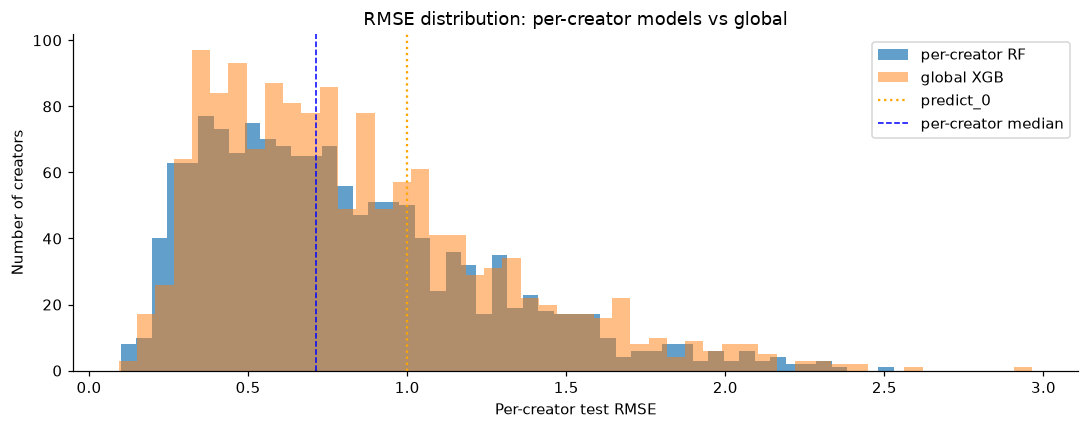

Creators where per-creator model > predict_0 on test: 395 / 1437


In [8]:
per_creator_pc = compute_per_creator_metrics(
    y_test[mask_valid], pd.Series(y_pred_best[mask_valid]), author_test[mask_valid]
)

# Also load global per-creator breakdown if available
pc_global_path = Path("results/per_creator_metrics_global.parquet")
if pc_global_path.exists():
    per_creator_global = pd.read_parquet(pc_global_path)
    merged = per_creator_pc.merge(per_creator_global[["author_id","rmse"]],
                                   on="author_id", suffixes=("_percreator", "_global"))
else:
    merged = per_creator_pc.rename(columns={"rmse": "rmse_percreator"})

print(f"Per-creator {best_name}: median RMSE={per_creator_pc['rmse'].median():.4f}  "
      f"mean={per_creator_pc['rmse'].mean():.4f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(per_creator_pc["rmse"], bins=50, alpha=0.7, label=f"per-creator {best_name}", edgecolor="none")
if "rmse_global" in merged.columns:
    ax.hist(merged["rmse_global"], bins=50, alpha=0.5, label="global XGB", edgecolor="none")
ax.axvline(rmse_zero, color="orange", linestyle=":", linewidth=1.5, label="predict_0")
ax.axvline(per_creator_pc["rmse"].median(), color="blue", linestyle="--", linewidth=1, label="per-creator median")
ax.set_xlabel("Per-creator test RMSE")
ax.set_ylabel("Number of creators")
ax.set_title("RMSE distribution: per-creator models vs global")
ax.legend()
plt.tight_layout()
plt.show()

n_worse_test = (per_creator_pc["rmse"] > rmse_zero).sum()
print(f"Creators where per-creator model > predict_0 on test: {n_worse_test} / {len(per_creator_pc)}")


## 6. Quality vs Creator Size


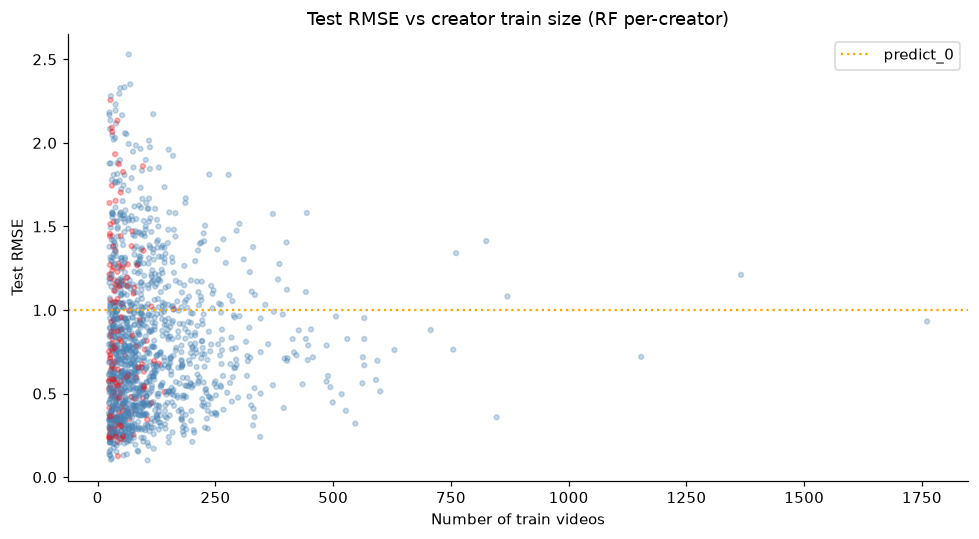

,mean,median,count
size_bin,,,
24-50,0.8040,0.6909,452
51-100,0.7835,0.6874,470
101-200,0.8140,0.7305,328
201-500,0.8007,0.7470,164
500+,0.7816,0.7604,23


In [9]:
# Attach n_train and worse_than_zero flag to per-creator metrics
n_train_map = {m.author_id: m.n_train for m in best_models.values()}
worse_map   = {m.author_id: m.worse_than_zero for m in best_models.values()}
per_creator_pc["n_train"]       = per_creator_pc["author_id"].map(n_train_map)
per_creator_pc["worse_than_zero"] = per_creator_pc["author_id"].map(worse_map)

fig, ax = plt.subplots(figsize=(9, 5))
colors = per_creator_pc["worse_than_zero"].map({True: "red", False: "steelblue"})
ax.scatter(per_creator_pc["n_train"], per_creator_pc["rmse"],
           alpha=0.3, s=10, c=colors)
ax.axhline(rmse_zero, color="orange", linestyle=":", linewidth=1.5, label="predict_0")
ax.set_xlabel("Number of train videos")
ax.set_ylabel("Test RMSE")
ax.set_title(f"Test RMSE vs creator train size ({best_name} per-creator)")
ax.legend()
plt.tight_layout()
plt.show()

# Bin by creator size
bins = [0, 50, 100, 200, 500, 10000]
labels = ["24-50", "51-100", "101-200", "201-500", "500+"]
per_creator_pc["size_bin"] = pd.cut(per_creator_pc["n_train"], bins=bins, labels=labels)
size_summary = per_creator_pc.groupby("size_bin", observed=True)["rmse"].agg(["mean", "median", "count"])
display(size_summary.style.format({"mean": "{:.4f}", "median": "{:.4f}"}))


## 7. Save Artefacts


In [10]:
import datetime
from creator_analytics.evaluate import log_experiment, save_metrics

today = datetime.date.today().isoformat()
exp_path = config["paths"].get("experiments_log", "results/experiments.md")
metrics_path = config["paths"].get("metrics", "results/metrics.json")

n_worse_rf_cv  = sum(m.worse_than_zero for m in rf_models.values())
n_worse_xgb_cv = sum(m.worse_than_zero for m in xgb_models.values())

log_experiment(exp_path, "per_creator_RF",  today, "non_constant_per_creator",
               "RF_per_creator",  rf_cfg,  float("nan"), m_rf,
               f"worse_than_zero_cv={n_worse_rf_cv}/{len(rf_models)}")
log_experiment(exp_path, "per_creator_XGB", today, "non_constant_per_creator",
               "XGB_per_creator", xgb_cfg, float("nan"), m_xgb,
               f"worse_than_zero_cv={n_worse_xgb_cv}/{len(xgb_models)}")

save_metrics({
    "per_creator_rf_test_rmse":           m_rf["rmse"],
    "per_creator_rf_test_r2":             m_rf["r2"],
    "per_creator_rf_worse_than_zero_cv":  n_worse_rf_cv,
    "per_creator_xgb_test_rmse":          m_xgb["rmse"],
    "per_creator_xgb_test_r2":            m_xgb["r2"],
    "per_creator_xgb_worse_than_zero_cv": n_worse_xgb_cv,
    "per_creator_winner":                 best_name,
}, metrics_path)

# Save predictions from winner
pred_path = Path("results/predictions_per_creator.parquet")
pred_path.parent.mkdir(parents=True, exist_ok=True)
pd.DataFrame({
    "y_true":    y_test.values,
    "y_pred":    y_pred_best,
    "author_id": author_test.values,
}).to_parquet(str(pred_path), index=False)

per_creator_pc.to_parquet("results/per_creator_metrics_percreator.parquet", index=False)

# Save models
for author_id, m in rf_models.items():
    m.save(f"models/per_creator/RF/{author_id}.joblib")
for author_id, m in xgb_models.items():
    m.save(f"models/per_creator/XGB/{author_id}.joblib")

print(f"Saved {len(rf_models)} RF + {len(xgb_models)} XGB creator models")
print(f"Saved: results/predictions_per_creator.parquet")
print(f"Saved: results/experiments.md")


Saved 1437 RF + 1437 XGB creator models
Saved: results/predictions_per_creator.parquet
Saved: results/experiments.md


## Summary

### Chosen configuration

**Why conservative?**  Creators have 24–1 700 train videos; on small sets a
deep unconstrained model overfits immediately.  The config is chosen by
averaging CV RMSE over 100 diverse creators — short trees, strong leaf
regularisation.

### Global metrics summary

| Model | Test RMSE | Test R² | Test Spearman |
|-------|-----------|---------|---------------|


In [11]:
print("=== Chosen configs ===")
print("RF :", {k: v for k, v in rf_cfg.items() if k != "n_estimators"})
print("XGB:", {k: v for k, v in xgb_cfg.items() if k not in ("n_estimators", "subsample", "colsample_bytree")})
print()

final_table = pd.DataFrame({
    "predict_0":            {"test_rmse": rmse_zero,   "test_r2": float("nan"), "test_spearman": float("nan")},
    "predict_creator_mean": {"test_rmse": rmse_cmean,  "test_r2": float("nan"), "test_spearman": float("nan")},
    "global_XGB":           {"test_rmse": m_global.get("rmse", float("nan")),
                              "test_r2":   m_global.get("r2",   float("nan")),
                              "test_spearman": m_global.get("spearman", float("nan"))},
    "per_creator_RF":       {"test_rmse": m_rf["rmse"],  "test_r2": m_rf["r2"],  "test_spearman": m_rf["spearman"]},
    "per_creator_XGB":      {"test_rmse": m_xgb["rmse"], "test_r2": m_xgb["r2"], "test_spearman": m_xgb["spearman"]},
}).T
display(final_table.style.format("{:.4f}", na_rep="—"))

n_worse_test = (per_creator_pc["rmse"] > rmse_zero).sum()
print(f"\nWinner: {best_name}")
print(f"Creators with test RMSE > predict_0: {n_worse_test} / {len(per_creator_pc)}")
print(f"Creators with CV RMSE > predict_0: RF={n_worse_rf_cv} / {len(rf_models)},  XGB={n_worse_xgb_cv} / {len(xgb_models)}")


=== Chosen configs ===
RF : {'max_depth': 4, 'min_samples_leaf': 5, 'max_features': 0.4}
XGB: {'max_depth': 3, 'min_child_weight': 5, 'reg_alpha': 1.0, 'reg_lambda': 2.0, 'learning_rate': 0.05}



,test_rmse,test_r2,test_spearman
predict_0,1.0005,—,—
predict_creator_mean,0.9690,—,—
global_XGB,0.9321,0.1133,0.2615
per_creator_RF,0.8931,0.1860,0.3776
per_creator_XGB,0.9023,0.1691,0.3838



Winner: RF
Creators with test RMSE > predict_0: 395 / 1437
Creators with CV RMSE > predict_0: RF=158 / 1437,  XGB=294 / 1437
